# Exercise 2: Euclidean Distance

**Subject:** Machine Learning Lab  
**Topic:** K-Nearest Neighbors (KNN)

## Aim
To calculate Euclidean distances between data points and understand how KNN uses distance to identify the nearest neighbors.

Query point: [3 4]

Euclidean distances:
Point 1: [1 2], Class: A, Distance: 2.828
Point 2: [2 3], Class: A, Distance: 1.414
Point 3: [3 3], Class: A, Distance: 1.000
Point 4: [6 7], Class: B, Distance: 4.243
Point 5: [7 8], Class: B, Distance: 5.657

The 3 nearest neighbors:
Point: [3 3], Class: A, Distance: 1.000
Point: [2 3], Class: A, Distance: 1.414
Point: [1 2], Class: A, Distance: 2.828

Predicted class: A


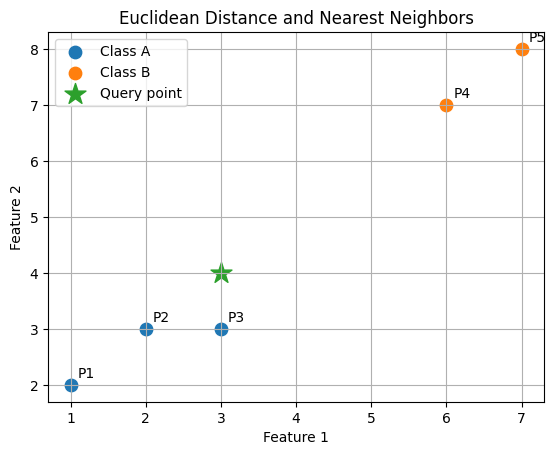

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# Define sample data points
points = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [6, 7],
    [7, 8]
])

labels = np.array(["A", "A", "A", "B", "B"])
query = np.array([3, 4])

# Calculate Euclidean distance from query to every point
distances = np.sqrt(np.sum((points - query) ** 2, axis=1))

print("Query point:", query)
print("\nEuclidean distances:")

for i, (point, distance, label) in enumerate(
    zip(points, distances, labels), start=1
):
    print(f"Point {i}: {point}, Class: {label}, Distance: {distance:.3f}")

# Identify the 3 nearest neighbors
k = 3
nearest_indices = np.argsort(distances)[:k]

print(f"\nThe {k} nearest neighbors:")
for idx in nearest_indices:
    print(f"Point: {points[idx]}, Class: {labels[idx]}, Distance: {distances[idx]:.3f}")

# Classify the query using majority vote
predicted_class = np.unique(
    labels[nearest_indices],
    return_counts=True
)
prediction = predicted_class[0][np.argmax(predicted_class[1])]

print("\nPredicted class:", prediction)

# Visualize points and query
for label in np.unique(labels):
    subset = points[labels == label]
    plt.scatter(subset[:, 0], subset[:, 1], label=f"Class {label}", s=80)

plt.scatter(query[0], query[1], marker="*", s=250, label="Query point")
for i, point in enumerate(points):
    plt.annotate(f"P{i+1}", point, xytext=(5, 5), textcoords="offset points")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Euclidean Distance and Nearest Neighbors")
plt.grid(True)
plt.legend()
plt.show()

## Result

Euclidean distances were calculated between the query point (3, 4) and five data points. The three nearest neighbors were identified, and majority voting was used to predict the query point's class.

- **Query point:** (3, 4)
- **Number of neighbors (k):** 3
- **Three nearest neighbors:** (3, 3), (2, 3), and (1, 2)
- **Predicted class:** A

The scatter plot visualized the data points, query point, and their classes.

## Conclusion

The experiment demonstrated how Euclidean distance measures the closeness between data points and how KNN uses the nearest neighbors to classify a new point. The query point was assigned to Class A because all three nearest neighbors belonged to Class A.